# KXHIGHLAX Realized-Vol Prediction

Predict future **noise-corrected realized vol** for the LA high-temp market from an
**EMA of past noise-corrected realized vol**, and check how accurate that prediction is
across a random sample of days over the past 6 months, at several forecast horizons
(10s, 1min, 10min, 30min, 1hr).

**Predictor:** split each day's finest (1s) implied-spot series into 1-minute bars, estimate
each bar's own realized variance via the two-scale (TSRV) noise correction already used
elsewhere in this project (`plotting.two_scale_realized_variance`), then EMA-smooth that
per-bar series. The EMA level, converted to a 1-day-equivalent vol rate, is the forecast --
scaled to each horizon via `sqrt(horizon in days)`, the same time-scaling `iv_scaled_to_day`
uses.

**Target:** the actual realized vol that occurs over `(t, t+horizon]`, measured the SAME
noise-corrected way (TSRV again, at a horizon-appropriate fast/slow split) -- comparing a
noise-corrected prediction against a naive/noisy target would just measure the correction
itself, not real forecast skill.

See `re_pred_functions.py` for the full method and every function used below -- this
notebook stays a thin sequence of calls into it, same convention `analysis.ipynb` /
`plotting.py` use.

In [1]:
import sys
import os
import importlib
_NB_DIR = os.path.dirname(os.path.abspath('__file__'))
sys.path.insert(0, _NB_DIR)
sys.path.insert(0, os.path.join(_NB_DIR, "..", "kalshi_infra"))

import datetime
from datetime import timezone, timedelta

import numpy as np
import pandas as pd

import api_functions
import black_scholes
import predexon_functions
import plotting
import re_pred_functions
importlib.reload(api_functions)
importlib.reload(black_scholes)
importlib.reload(predexon_functions)
importlib.reload(plotting)
importlib.reload(re_pred_functions)

from api_functions import event_ticker_from_date
from black_scholes import compute_implied_spot_timeseries_cached
from predexon_functions import load_predexon_long_df

## Day fetch helper

Same `fetch_day_timeseries` as `analysis.ipynb` -- wires a day's event ticker + full
48h market-lifetime window into `compute_implied_spot_timeseries_cached`, which only
does real work (a live Predexon call) on an actual cache miss. Every date used below is
already cached locally at every frequency this notebook needs (`1s` for the backtest
itself, `1min` for the cheap gap-fraction quality check).

In [2]:
def day_window_ts(date):
    event_start_pt = plotting.LA_TZ.localize(datetime.datetime(date.year, date.month, date.day))
    start = event_start_pt - timedelta(days=1)
    end = event_start_pt + timedelta(days=1)
    now = int(datetime.datetime.now(timezone.utc).timestamp())
    return int(start.timestamp()), min(int(end.timestamp()), now)


def fetch_day_timeseries(date, freq='1s', max_lookback=None):
    event_ticker = event_ticker_from_date(date)
    start_ts, end_ts = day_window_ts(date)
    ts_df = compute_implied_spot_timeseries_cached(
        lambda: load_predexon_long_df(event_ticker),
        start_ts, end_ts, event_ticker, freq=freq, max_lookback=max_lookback,
    )
    return event_ticker, ts_df

## Day selection

Random sample of days from the trailing 6 months of locally cached data (`black_scholes.
list_cached_days` -- no live Predexon calls, no hardcoded date list), dropping any day
whose 1min-grid gap fraction (`plotting._gap_fraction` -- % of the day a lambda_min-rejected
fit left untrustworthy) is at or above `GAP_THRESHOLD`, same convention `analysis.ipynb`'s
`SPOT_PLOT_DAYS` uses. Rejected draws are dropped, not replaced from outside the 6-month
window -- see `sample_backtest_days`'s docstring.

In [3]:
GAP_THRESHOLD = 0.05
N_SAMPLE_DAYS = 30
MONTHS_BACK = 6
RANDOM_SEED = 42

CACHED_DAYS = black_scholes.list_cached_days(freq='1s')
print(f'{len(CACHED_DAYS)} cached days locally, {CACHED_DAYS[0]} .. {CACHED_DAYS[-1]}')

# Exclude the most recent day: 1s history for "today" can still be an
# in-progress/open market rather than a closed historical day.
AS_OF = CACHED_DAYS[-1] - datetime.timedelta(days=1)


def _gap_ok(date):
    _, df = fetch_day_timeseries(date, freq='1min')
    if df.empty:
        return False
    return plotting._gap_fraction(df, date) < GAP_THRESHOLD


BACKTEST_DAYS = re_pred_functions.sample_backtest_days(
    CACHED_DAYS, N_SAMPLE_DAYS, months_back=MONTHS_BACK, as_of=AS_OF,
    gap_check=_gap_ok, seed=RANDOM_SEED,
)
print(f'{len(BACKTEST_DAYS)} days sampled from the trailing {MONTHS_BACK} months '
      f'(of {N_SAMPLE_DAYS} drawn, as of {AS_OF}):')
print(BACKTEST_DAYS)

191 cached days locally, 2026-01-07 .. 2026-08-03


22 days sampled from the trailing 6 months (of 30 drawn, as of 2026-08-02):
[datetime.date(2026, 2, 4), datetime.date(2026, 2, 9), datetime.date(2026, 2, 10), datetime.date(2026, 2, 11), datetime.date(2026, 3, 1), datetime.date(2026, 3, 10), datetime.date(2026, 4, 1), datetime.date(2026, 4, 2), datetime.date(2026, 4, 3), datetime.date(2026, 4, 5), datetime.date(2026, 4, 8), datetime.date(2026, 4, 16), datetime.date(2026, 5, 4), datetime.date(2026, 5, 24), datetime.date(2026, 5, 25), datetime.date(2026, 5, 31), datetime.date(2026, 6, 15), datetime.date(2026, 6, 25), datetime.date(2026, 7, 8), datetime.date(2026, 7, 22), datetime.date(2026, 7, 25), datetime.date(2026, 8, 2)]


## Predictor config

`bar_freq`: granularity of the per-bar noise-corrected variance observations the EMA runs
over. `ema_halflife`: how much weight decays by half per that many minutes -- shorter
reacts faster to a genuine vol-regime change, longer smooths out per-bar TSRV noise more.
`eval_stride`: how often (in calendar time) a fresh prediction is scored in the backtest --
independent of `bar_freq`, just controls backtest density/runtime.

In [4]:
BAR_FREQ = '1min'
EMA_HALFLIFE = '20min'
EVAL_STRIDE = '5min'
PREDICTOR_SLOW_FREQ = '10s'

print(f'bar_freq={BAR_FREQ}  ema_halflife={EMA_HALFLIFE}  eval_stride={EVAL_STRIDE}  '
      f'predictor_slow_freq={PREDICTOR_SLOW_FREQ}')
print(f'horizons: {re_pred_functions.HORIZONS}')

bar_freq=1min  ema_halflife=20min  eval_stride=5min  predictor_slow_freq=10s
horizons: ['10s', '1min', '10min', '30min', '1hr']


## Run the backtest

Fetches each sampled day's 1s implied-spot series (cache hit, so this is just a parquet
read -- no live Predexon calls) and runs `re_pred_functions.build_predictions` on it,
producing one (predicted, actual) noise-corrected-vol pair per (evaluation time, horizon).

In [5]:
all_results = []
for d in BACKTEST_DAYS:
    ticker, df_1s = fetch_day_timeseries(d, freq='1s')
    if df_1s.empty:
        print(f'{d}: no 1s data, skipping')
        continue
    day_results = re_pred_functions.build_predictions(
        df_1s, d, horizons=re_pred_functions.HORIZONS, bar_freq=BAR_FREQ,
        ema_halflife=EMA_HALFLIFE, eval_stride=EVAL_STRIDE,
        predictor_slow_freq=PREDICTOR_SLOW_FREQ,
    )
    print(f'{ticker} ({d}): {len(day_results)} (time, horizon) predictions')
    all_results.append(day_results)

results = pd.concat(all_results, ignore_index=True)
print(f'\n{len(results)} total predictions across {len(BACKTEST_DAYS)} days')
results.groupby('horizon').size().reindex(re_pred_functions.HORIZONS)

KXHIGHLAX-26FEB04 (2026-02-04): 2168 (time, horizon) predictions


KXHIGHLAX-26FEB09 (2026-02-09): 2100 (time, horizon) predictions


KXHIGHLAX-26FEB10 (2026-02-10): 2180 (time, horizon) predictions


KXHIGHLAX-26FEB11 (2026-02-11): 2180 (time, horizon) predictions


KXHIGHLAX-26MAR01 (2026-03-01): 2125 (time, horizon) predictions


...

KXHIGHLAX-26JUL08 (2026-07-08): 1675 (time, horizon) predictions


KXHIGHLAX-26JUL22 (2026-07-22): 2180 (time, horizon) predictions


KXHIGHLAX-26JUL25 (2026-07-25): 2180 (time, horizon) predictions


KXHIGHLAX-26AUG02 (2026-08-02): 2180 (time, horizon) predictions

47303 total predictions across 22 days


horizon
10s      9543
1min     9544
10min    9508
30min    9420
1hr      9288
dtype: int64

## Accuracy by horizon

MSE/RMSE/MAE/correlation/R² in both variance space (the statistically appropriate scale
for scoring a variance estimator) and vol space (raw °F, more legible), plus QLIKE -- the
standard heteroskedasticity-robust variance-forecast loss, which penalizes an overconfident
LOW forecast that actual vol blew past far more than an equally-sized overcautious HIGH
one. See `compute_metrics`'s docstring.

In [6]:
metrics_var = re_pred_functions.compute_metrics(results, space='var')
metrics_vol = re_pred_functions.compute_metrics(results, space='vol')

print('--- variance space ---')
display(metrics_var)
print('\n--- vol space (degF) ---')
display(metrics_vol)

--- variance space ---


,n,mse,rmse,mae,r2,corr,qlike,qlike_median,mean_predicted,mean_actual
horizon,,,,,,,,,,
10s,9543,0.000067,0.008167,0.000653,0.024373,0.190871,1.859019e+01,16.543277,0.000253,0.000479
1min,9544,0.000496,0.022265,0.002435,0.034668,0.186276,3.619561e+06,7.857811,0.001523,0.001647
10min,9508,0.006584,0.081143,0.019350,-0.014024,0.248125,2.204117e+05,1.063986,0.015340,0.015960
30min,9420,0.032927,0.181457,0.056193,-0.027331,0.334578,1.498707e+05,0.763281,0.046331,0.051938
1hr,9288,0.104471,0.323219,0.112294,-0.163607,0.329468,1.292834e+05,0.669378,0.093955,0.106846



--- vol space (degF) ---


,n,mse,rmse,mae,r2,corr,qlike,qlike_median,mean_predicted,mean_actual
horizon,,,,,,,,,,
10s,9543,0.000519,0.022786,0.011159,-0.122676,0.248563,NaN,NaN,0.010659,0.004070
1min,9544,0.001738,0.041693,0.022371,-0.175323,0.338365,NaN,NaN,0.026127,0.012964
10min,9508,0.011457,0.107036,0.056972,-0.013423,0.435455,NaN,NaN,0.083093,0.068230
30min,9420,0.030560,0.174813,0.095601,0.048839,0.471353,NaN,NaN,0.145100,0.140745
1hr,9288,0.059433,0.243789,0.138026,0.008444,0.465167,NaN,NaN,0.207952,0.216580


## Example day

One sampled day's implied spot alongside the EMA noise-corrected vol-rate signal that
every horizon's forecast is scaled from.

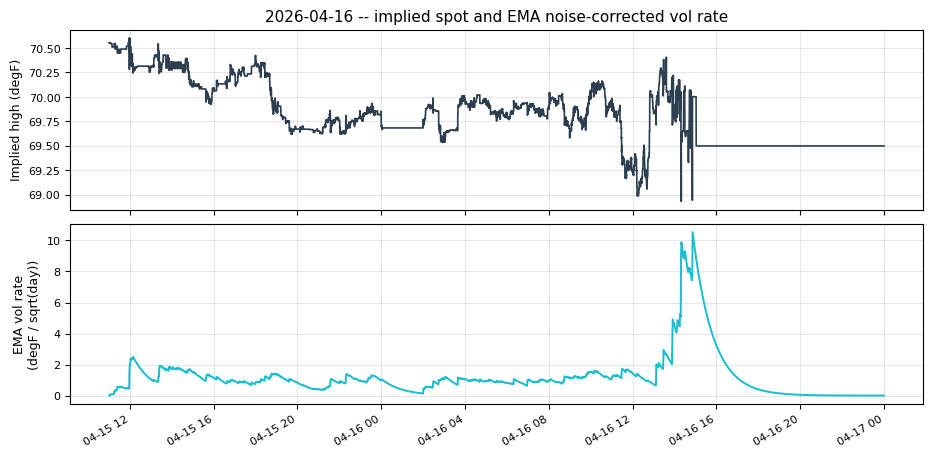

In [7]:
example_date = BACKTEST_DAYS[len(BACKTEST_DAYS) // 2]
_, example_df = fetch_day_timeseries(example_date, freq='1s')
fig = re_pred_functions.plot_example_day(
    example_df, example_date, bar_freq=BAR_FREQ, ema_halflife=EMA_HALFLIFE,
    predictor_slow_freq=PREDICTOR_SLOW_FREQ,
)

## Predicted vs. actual, by horizon

Each panel: predicted vs. actual noise-corrected realized vol for one horizon, with a
y=x reference line -- a well-calibrated forecast clusters along it; a cloud consistently
above/below it is a systematic over/under-forecast at that horizon.

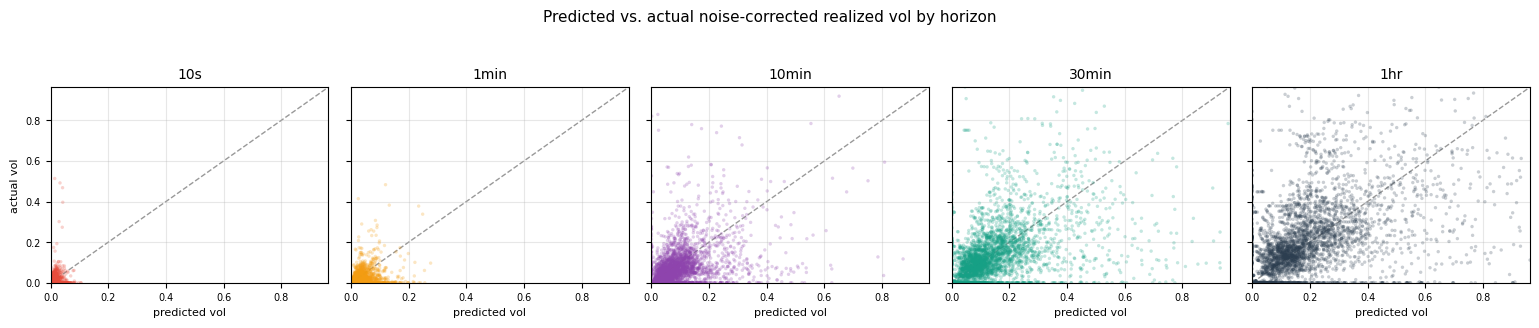

In [8]:
fig = re_pred_functions.plot_predicted_vs_actual(results, space='vol')

## RMSE by horizon

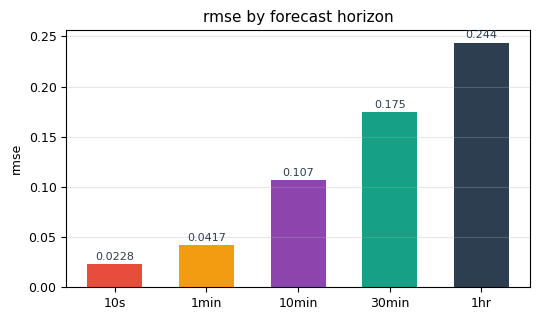

In [9]:
fig = re_pred_functions.plot_metrics_bar(metrics_vol, metric='rmse')